# 04 · Modelos de Regresión — ¿Cuánta popularidad tendrá?

**Pregunta de negocio:** estimar la popularidad (1–100) de una canción para priorizar inversión y negociar contratos.

- **Target:** `popularity` sin transformar, para que el error se lea en puntos de popularidad
- **Mismo split y mismas features** que en clasificación (NB03)

> Este notebook carga los resultados de `kedro run`, no reentrena.

### Modelos y justificación

| Modelo | Por qué | Configuración clave |
|---|---|---|
| **Baseline** (DummyRegressor) | Piso de referencia: siempre predice la media | `strategy=mean` |
| **Ridge** | Regresión lineal con penalización L2: maneja la multicolinealidad del EDA (energy–loudness r=0.76) y el One-Hot completo | `alpha=1.0` |
| **Random Forest** | Relaciones no lineales sin supuestos de forma | 200 árboles, `max_depth=20`, `min_samples_leaf=5`, `max_features=0.3` |
| **Gradient Boosting** (HistGradientBoosting) | Mejor rendimiento esperado en datos tabulares | RandomizedSearchCV (15 combinaciones × 3 folds, optimizando MAE) |

### Métricas

- **MAE** (principal): error promedio en puntos de popularidad. Fácil de explicar al negocio.
- **RMSE**: penaliza más los errores grandes.
- **R²**: proporción de la variabilidad de popularity que explica el modelo.

In [1]:
%load_ext kedro.ipython

The kedro.ipython extension is already loaded. To reload it, use:
  %reload_ext kedro.ipython


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 90
pd.set_option("display.max_colwidth", 120)

PLOTS = "../results/plots"
params = catalog.load("parameters")

                    INFO     Loading data from parameters (MemoryDataset)...                   ]8;id=9723805;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=9723806;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

## 1. Optimización de hiperparámetros — Gradient Boosting

In [3]:
hp = catalog.load("hyperparameter_results_reg")
hp["MAE_cv"] = -hp["mean_test_score"]
hp[["rank_test_score", "MAE_cv", "std_test_score", "params"]].head(5)

                    INFO     Loading data from hyperparameter_results_reg (CSVDataset)...      ]8;id=9723811;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=9723812;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,rank_test_score,MAE_cv,std_test_score,params
0,1,8.899878,0.038527,"{'min_samples_leaf': 50, 'max_leaf_nodes': 127, 'max_iter': 800, 'learning_rate': 0.05, 'l2_regularization': 0.0}"
1,2,8.906462,0.040791,"{'min_samples_leaf': 20, 'max_leaf_nodes': 127, 'max_iter': 200, 'learning_rate': 0.03, 'l2_regularization': 0.1}"
2,3,8.915583,0.030530,"{'min_samples_leaf': 50, 'max_leaf_nodes': 127, 'max_iter': 200, 'learning_rate': 0.05, 'l2_regularization': 1.0}"
3,4,8.923843,0.055006,"{'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_iter': 800, 'learning_rate': 0.03, 'l2_regularization': 0.0}"
4,5,8.929281,0.035712,"{'min_samples_leaf': 20, 'max_leaf_nodes': 31, 'max_iter': 200, 'learning_rate': 0.1, 'l2_regularization': 0.0}"


Igual que en clasificación, ganan los árboles con más hojas (`max_leaf_nodes=127`). La diferencia entre las 8 mejores combinaciones es de menos de 0.04 puntos de MAE: el resultado no depende de un ajuste fino.

## 2. Métricas en test

In [4]:
reg_metrics = catalog.load("reg_test_metrics")
reg_metrics.style.highlight_min(subset=["MAE", "RMSE"], color="#C8F7C5").highlight_max(subset=["R2"], color="#C8F7C5").format(precision=3)

                    INFO     Loading data from reg_test_metrics (CSVDataset)...                ]8;id=9723817;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=9723818;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,Modelo,MAE,RMSE,R2
0,Baseline,14.882,17.792,-0.000
1,Ridge,9.127,12.547,0.503
2,RandomForest,10.739,13.861,0.393
3,GradientBoosting,8.654,12.134,0.535


**Interpretación:**

- El **Baseline** se equivoca en promedio **14.9 puntos**.
- **Gradient Boosting** baja el error a **8.65 puntos** (−42%) y explica el **53.5%** de la variabilidad (R² = 0.535).
- **Ridge** queda segundo (MAE 9.13, R² 0.50): de nuevo, gran parte de la señal es aditiva (efecto del género).
- **Random Forest** es el peor modelo no trivial (MAE 10.7, R² 0.39). Una explicación probable: el género está repartido en 114 columnas One-Hot y cada división de un árbol solo separa un género del resto, por lo que con `max_depth=20` le cuesta aprovecharlo. Boosting y Ridge, en cambio, acumulan el efecto de cada género de forma aditiva.

## 3. Validación cruzada (5 folds)

In [5]:
cv = catalog.load("cv_reg_results")
cv

                    INFO     Loading data from cv_reg_results (CSVDataset)...                  ]8;id=9723823;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=9723824;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,Modelo,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
0,Ridge,9.2812,0.0515,12.6980,0.0618,0.4946,0.0062
1,RandomForest,10.8249,0.0606,13.9386,0.0728,0.3911,0.0054
2,GradientBoosting,8.8514,0.0467,12.3396,0.0728,0.5228,0.0057


Los resultados de CV coinciden con test (GB: MAE 8.85 en CV vs 8.65 en test) con desviaciones muy bajas (< 0.07): **modelos estables, sin sobreajuste**.

## 4. Real vs predicho

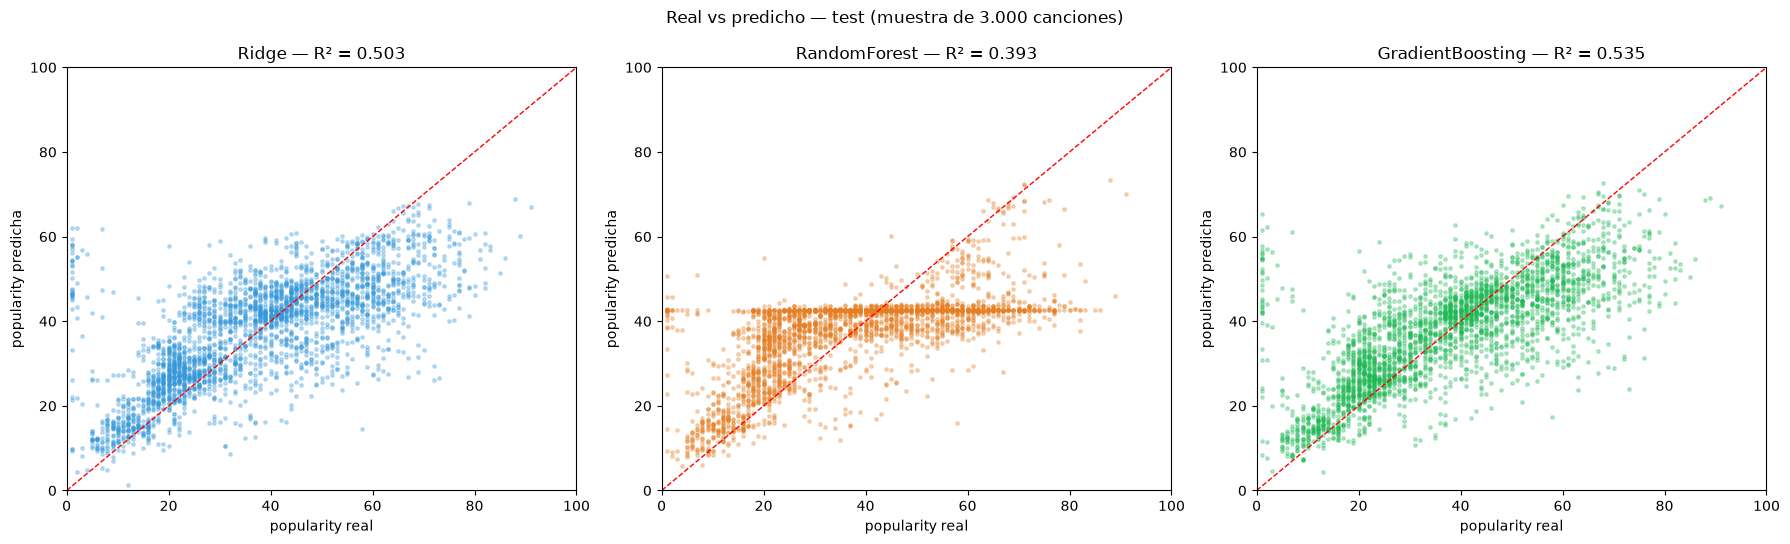

In [6]:
display(Image(f"{PLOTS}/04_reg_real_vs_pred.png"))

In [7]:
X_test = catalog.load("X_test")
y_test = catalog.load("y_test_reg").squeeze()
gb = catalog.load("gradient_boosting_reg")
pred = gb.predict(X_test)
error = y_test - pred

print(f"Error absoluto mediano: {np.median(np.abs(error)):.1f} puntos")
print(f"Predicciones a ±10 puntos del valor real: {(np.abs(error) <= 10).mean():.1%}")

rangos = pd.cut(y_test, [0, 20, 40, 60, 80, 100], include_lowest=True)
por_rango = pd.DataFrame({"real": y_test, "error_abs": np.abs(error), "sesgo": error}).groupby(rangos, observed=True).agg(
    canciones=("real", "size"), MAE=("error_abs", "mean"), sesgo_medio=("sesgo", "mean"))
por_rango.round(2)

                    INFO     Loading data from X_test (CSVDataset)...                          ]8;id=9723829;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=9723830;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

[10/19/26 23:04:24] INFO     Loading data from y_test_reg (CSVDataset)...                      ]8;id=9723835;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=9723836;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

                    INFO     Loading data from gradient_boosting_reg (PickleDataset)...        ]8;id=9723841;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=9723842;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

Error absoluto mediano: 6.1 puntos
Predicciones a ±10 puntos del valor real: 68.9%


,canciones,MAE,sesgo_medio
popularity,,,
"(-0.001, 20.0]",2828,10.19,-9.71
"(20.0, 40.0]",5799,6.81,-4.68
"(40.0, 60.0]",4948,7.34,5.13
"(60.0, 80.0]",1631,15.48,15.19
"(80.0, 100.0]",82,29.34,29.34


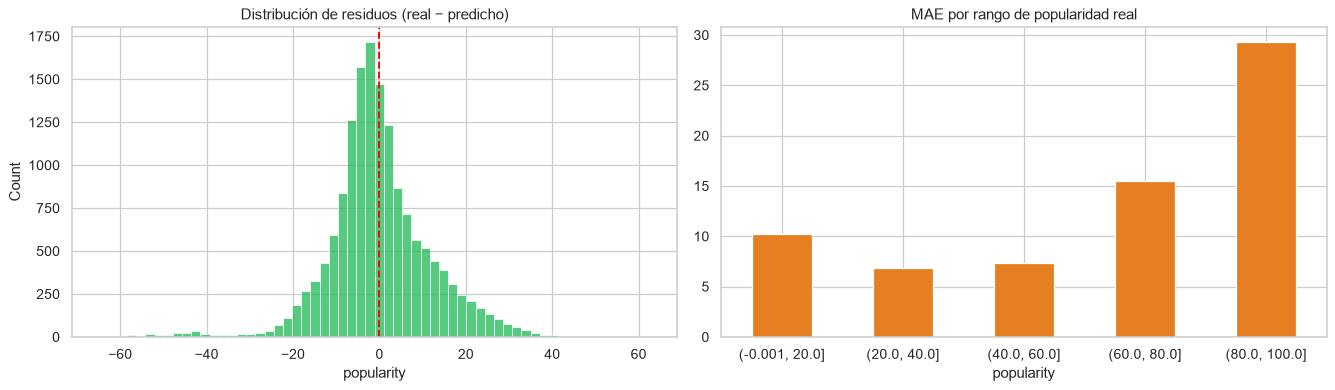

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(error, bins=60, ax=axes[0], color="#1DB954")
axes[0].axvline(0, color="red", ls="--")
axes[0].set_title("Distribución de residuos (real − predicho)")
por_rango["MAE"].plot.bar(ax=axes[1], color="#E67E22", rot=0)
axes[1].set_title("MAE por rango de popularidad real")
plt.tight_layout()
plt.show()

- La mitad de las predicciones se equivoca en **6 puntos o menos** y el 69% queda a ±10 puntos.
- Los residuos están centrados en 0, pero el error **no es uniforme**: el modelo es mejor en el rango medio (20–60) y **subestima las canciones muy populares (> 60)** y sobreestima las muy poco populares. Es el típico efecto de "regresión a la media": con las variables disponibles, el modelo no puede anticipar qué canción se vuelve un éxito masivo (eso depende del artista, marketing, viralidad, etc.).

## 5. Importancia de variables

In [9]:
catalog.load("feature_importance")[["Variable", "aumento_MAE_reg"]].sort_values("aumento_MAE_reg", ascending=False).head(10)

                    INFO     Loading data from feature_importance (CSVDataset)...              ]8;id=9723847;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=9723848;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,Variable,aumento_MAE_reg
0,track_genre,7.1917
5,instrumentalness,0.6873
2,energy,0.3581
1,duration_min,0.2286
3,acousticness,0.2104
4,loudness,0.1986
8,danceability,0.1510
9,speechiness,0.1368
7,valence,0.1114
10,explicit,0.0852


Al permutar el género el MAE sube **7.2 puntos** (de 8.65 a ~15.8, peor que el baseline). Entre las variables de audio, `instrumentalness` es la más relevante (+0.69): las canciones instrumentales tienden a ser menos populares.

## Conclusiones

1. **Gradient Boosting** es el mejor regresor: MAE = 8.65 puntos, R² = 0.535, 42% menos error que el baseline.
2. Es útil para **estimar el rango de popularidad** (bajo / medio / alto) de una canción, no para predecir el valor exacto.
3. Para identificar éxitos, el modelo de **clasificación** (NB03) es más adecuado: la regresión subestima sistemáticamente las canciones más populares.
4. Un R² de 0.53 indica que casi la mitad de la popularidad depende de factores **fuera del dataset** (artista, marketing, fecha de lanzamiento).